# Cooling Check: Weather-Normalized Building Anomaly Detection

## Section 1: Framing

### Who it's for
**Facility operators** — people responsible for keeping buildings running efficiently and spotting when cooling systems aren't performing as expected.

### The Question
**Is this building's cooling running worse than the weather explains?**

### What this is NOT
- Not production code or a real-time monitoring system
- Not a perfect physics model (simplified, linear)
- Not a replacement for domain expertise

### Approach
1. Physics baseline: change-point model (ASHRAE Guideline 14)
2. ML on residual: occupancy + operational patterns
3. Uncertainty: 90% prediction bands
4. Backtest: rolling-origin, no leakage
5. Cold start: transfer learning for new buildings
6. Drift: detect equipment degradation
7. Actionable: flag anomalies, $ and CO₂

---

## Section 2: Data

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

# Load data
ASHRAE_PATH = 'ashrae-energy-prediction'
metadata = pd.read_csv(f'{ASHRAE_PATH}/building_metadata.csv')
train_raw = pd.read_csv(f'{ASHRAE_PATH}/train.csv')
weather_raw = pd.read_csv(f'{ASHRAE_PATH}/weather_train.csv')

# Filter to meter 1 (chilled water)
meter_1 = train_raw[train_raw['meter'] == 1].copy()

# Select 7 buildings from Site 0 (largest by sq ft)
site_0_meta = metadata[(metadata['site_id'] == 0) & (metadata['building_id'].isin(meter_1['building_id']))]
SELECTED_BUILDINGS = site_0_meta.nlargest(7, 'square_feet')['building_id'].values
SITE_ID = 0

print(f"Site: {SITE_ID}")
print(f"Selected buildings: {SELECTED_BUILDINGS}")
print(f"\nBuilding details:")
print(site_0_meta.loc[site_0_meta['building_id'].isin(SELECTED_BUILDINGS), 
                      ['building_id', 'primary_use', 'square_feet', 'year_built']])

Site: 0
Selected buildings: [95 96 98 97 76  7 29]

Building details:
    building_id          primary_use  square_feet  year_built
7             7            Education       121074      1989.0
29           29            Education       113866      2006.0
76           76            Education       128887      2009.0
95           95  Lodging/residential       200933      2006.0
96           96  Lodging/residential       200933      2006.0
97           97  Lodging/residential       187647      2007.0
98           98  Lodging/residential       200933      2007.0


### Look at the raw data before cleaning

Where do the zero readings fall in time, how long do they last, and do several buildings go to zero at the same hour?

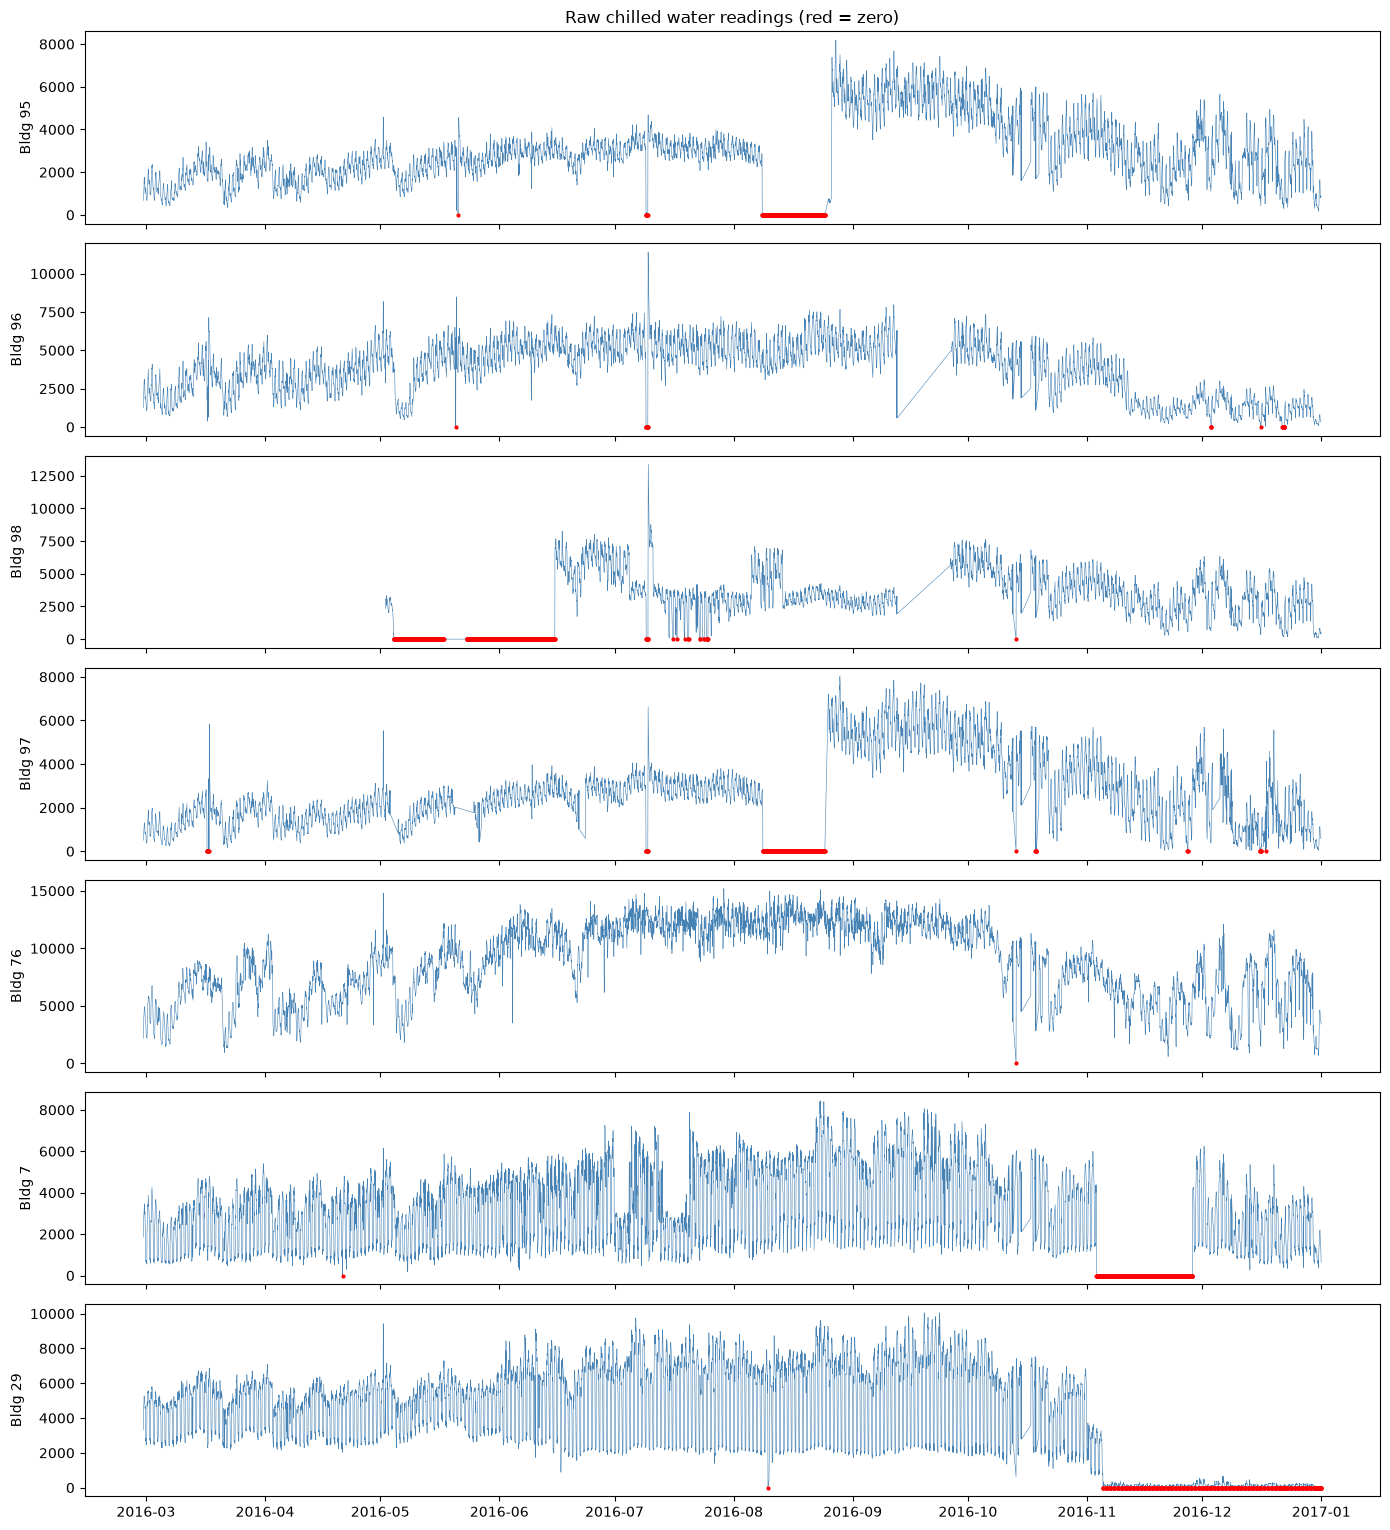

 building_id       first_reading  n_zeros  n_zero_runs  longest_run_hrs          first_zero           last_zero
          95 2016-02-29 09:00:00      402            4              393 2016-05-21 09:00:00 2016-08-24 19:00:00
          96 2016-02-29 09:00:00       30            6               12 2016-05-20 16:00:00 2016-12-22 09:00:00
          98 2016-05-02 10:00:00      892           12              859 2016-05-04 13:00:00 2016-10-13 13:00:00
          97 2016-02-29 09:00:00      426           13              388 2016-03-16 22:00:00 2016-12-17 13:00:00
          76 2016-02-29 09:00:00        1            1                1 2016-10-13 13:00:00 2016-10-13 13:00:00
           7 2016-02-29 09:00:00      602            2              601 2016-04-21 05:00:00 2016-11-28 11:00:00
          29 2016-02-29 09:00:00      469           62               20 2016-08-09 23:00:00 2016-12-31 23:00:00

Hours by number of buildings reading zero at the same time:
0    5069
1    1605
2     581
3       9
4  

In [15]:
raw_sel = meter_1[meter_1['building_id'].isin(SELECTED_BUILDINGS)].copy()
raw_sel['timestamp'] = pd.to_datetime(raw_sel['timestamp'])
raw_sel = raw_sel.sort_values(['building_id', 'timestamp'])

fig, axes = plt.subplots(len(SELECTED_BUILDINGS), 1, figsize=(14, 2.2 * len(SELECTED_BUILDINGS)), sharex=True)
rows = []
for ax, b_id in zip(axes, SELECTED_BUILDINGS):
    b = raw_sel[raw_sel['building_id'] == b_id]
    zero = b['meter_reading'] == 0
    ax.plot(b['timestamp'], b['meter_reading'], lw=0.4, color='steelblue')
    ax.scatter(b.loc[zero, 'timestamp'], b.loc[zero, 'meter_reading'], s=4, color='red', zorder=3)
    ax.set_ylabel(f'Bldg {b_id}')

    run_id = (zero != zero.shift()).cumsum()
    zero_runs = zero.groupby(run_id).agg(['all', 'size'])
    zero_runs = zero_runs[zero_runs['all']]['size']
    rows.append({
        'building_id': b_id,
        'first_reading': b['timestamp'].min(),
        'n_zeros': int(zero.sum()),
        'n_zero_runs': len(zero_runs),
        'longest_run_hrs': int(zero_runs.max()) if len(zero_runs) else 0,
        'first_zero': b.loc[zero, 'timestamp'].min(),
        'last_zero': b.loc[zero, 'timestamp'].max(),
    })

axes[0].set_title('Raw chilled water readings (red = zero)')
plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).to_string(index=False))

# How many of the selected buildings read zero at the same hour?
zero_wide = raw_sel.assign(is_zero=raw_sel['meter_reading'] == 0).pivot_table(
    index='timestamp', columns='building_id', values='is_zero', aggfunc='max')
print("\nHours by number of buildings reading zero at the same time:")
print(zero_wide.sum(axis=1).value_counts().sort_index())

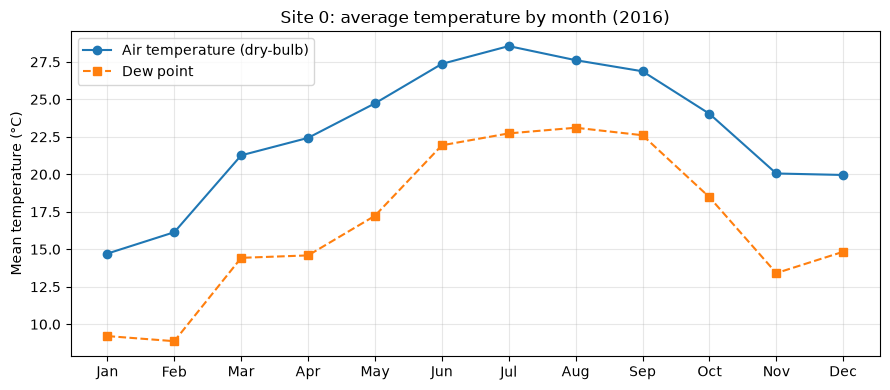

       air_temperature  dew_temperature
month                                  
1                 14.7              9.2
2                 16.1              8.9
3                 21.3             14.4
4                 22.4             14.6
5                 24.7             17.2
6                 27.4             21.9
7                 28.6             22.7
8                 27.6             23.1
9                 26.9             22.6
10                24.0             18.5
11                20.1             13.4
12                20.0             14.8


In [10]:
import os
os.makedirs('figures', exist_ok=True)

w0 = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
w0['month'] = pd.to_datetime(w0['timestamp']).dt.month
monthly = w0.groupby('month')[['air_temperature', 'dew_temperature']].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly['air_temperature'], 'o-', label='Air temperature (dry-bulb)')
ax.plot(monthly.index, monthly['dew_temperature'], 's--', label='Dew point')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_ylabel('Mean temperature (°C)')
ax.set_title(f'Site {SITE_ID}: average temperature by month (2016)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/site0_monthly_temperature.png', dpi=120)
plt.show()

print(monthly.round(1))


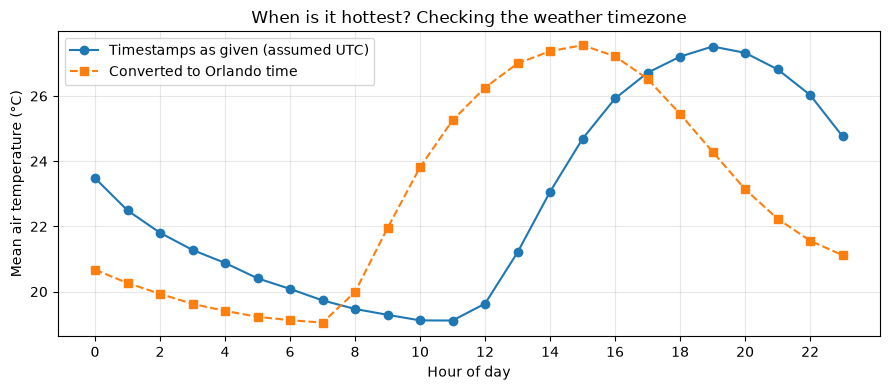

Hottest hour, timestamps as given: 19
Hottest hour, Orlando time:       15


In [16]:
wx = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
wx['ts_utc'] = pd.to_datetime(wx['timestamp']).dt.tz_localize('UTC')
wx['ts_local'] = wx['ts_utc'].dt.tz_convert('America/New_York')

by_hour_utc = wx.groupby(wx['ts_utc'].dt.hour)['air_temperature'].mean()
by_hour_local = wx.groupby(wx['ts_local'].dt.hour)['air_temperature'].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_hour_utc.index, by_hour_utc.values, 'o-', label='Timestamps as given (assumed UTC)')
ax.plot(by_hour_local.index, by_hour_local.values, 's--', label='Converted to Orlando time')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hour of day')
ax.set_ylabel('Mean air temperature (°C)')
ax.set_title('When is it hottest? Checking the weather timezone')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/site0_timezone_check.png', dpi=120)
plt.show()

print("Hottest hour, timestamps as given:", by_hour_utc.idxmax())
print("Hottest hour, Orlando time:      ", by_hour_local.idxmax())


In [19]:
ZERO_RUN_LIMIT_HRS = 24   # Miller et al. 2020 (BDG2): zero runs longer than 24 hours are bad data
LOW_FRACTION = 0.10       # "stuck low": daily median below 10% of the building's usual daily median
MIN_STUCK_DAYS = 7        # our choice: only flag low stretches lasting at least a week

def find_stuck_low_start(df):
    daily = df.set_index('timestamp')['meter_reading'].resample('D').median()
    is_low = daily < LOW_FRACTION * daily.median()
    if not is_low.iloc[-1]:
        return None
    start = is_low[~is_low].index.max() + pd.Timedelta(days=1)
    if (daily.index.max() - start).days + 1 < MIN_STUCK_DAYS:
        return None
    return start

def clean_building_data(building_id, meter_1_df):
    df = meter_1_df[meter_1_df['building_id'] == building_id].copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.sort_values('timestamp').drop_duplicates(subset='timestamp', keep='first').reset_index(drop=True)

    df['flag'] = ''

    is_zero = df['meter_reading'] == 0
    run_id = (is_zero != is_zero.shift()).cumsum()
    run_length = is_zero.groupby(run_id).transform('size')
    df.loc[is_zero & (run_length > ZERO_RUN_LIMIT_HRS), 'flag'] = 'long_zero_run'

    low_start = find_stuck_low_start(df)
    if low_start is not None:
        df.loc[(df['timestamp'] >= low_start) & (df['flag'] == ''), 'flag'] = 'stuck_low'

    return df, low_start

cleaned_data = {}
rows = []
for b_id in SELECTED_BUILDINGS:
    df, low_start = clean_building_data(b_id, meter_1)
    cleaned_data[b_id] = df
    counts = df['flag'].replace('', 'ok').value_counts()
    rows.append({'building_id': b_id,
                 'hours': len(df),
                 'ok': counts.get('ok', 0),
                 'long_zero_run': counts.get('long_zero_run', 0),
                 'stuck_low': counts.get('stuck_low', 0),
                 'stuck_low_starts': low_start.date() if low_start is not None else '-'})

flag_summary = pd.DataFrame(rows).set_index('building_id')
print(flag_summary)


             hours    ok  long_zero_run  stuck_low stuck_low_starts
building_id                                                        
95            7244  6851            393          0                -
96            6933  6933              0          0                -
98            5279  4420            859          0                -
97            6997  6609            388          0                -
76            7269  7269              0          0                -
7             7267  6666            601          0                -
29            7269  5901              0       1368       2016-11-05


In [21]:
# Weather for Site 0
weather = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
weather['timestamp'] = (pd.to_datetime(weather['timestamp'])
                        .dt.tz_localize('UTC')
                        .dt.tz_convert('America/New_York')
                        .dt.tz_localize(None))
weather = weather.drop_duplicates(subset='timestamp', keep='first')
weather_use = weather[['timestamp', 'air_temperature', 'dew_temperature']].copy()
weather_use = weather_use.dropna(subset=['air_temperature', 'dew_temperature'])

print(f"Weather: {len(weather_use)} hours")
print(f"Temperature range: {weather_use['air_temperature'].min():.1f}°C to {weather_use['air_temperature'].max():.1f}°C")

# Merge data
all_data = []
for b_id in SELECTED_BUILDINGS:
    df = cleaned_data[b_id][['timestamp', 'meter_reading', 'flag']].copy()
    df['building_id'] = b_id
    all_data.append(df)

energy_df = pd.concat(all_data, ignore_index=True).sort_values(['building_id', 'timestamp'])
data = energy_df.merge(weather_use, on='timestamp', how='inner')

# Add time features
data['hour'] = data['timestamp'].dt.hour
data['day_of_week'] = data['timestamp'].dt.dayofweek
data['month'] = data['timestamp'].dt.month
data['is_weekend'] = data['day_of_week'] >= 5

data = data.merge(metadata[['building_id', 'primary_use', 'square_feet']], on='building_id', how='left')

print(f"\nFinal dataset: {data.shape}")
print(f"Date range: {data['timestamp'].min()} to {data['timestamp'].max()}")
print(f"Buildings: {data['building_id'].nunique()}")

Weather: 8780 hours
Temperature range: 1.7°C to 36.1°C

Final dataset: (48217, 12)
Date range: 2016-02-29 09:00:00 to 2016-12-31 18:00:00
Buildings: 7


---

## Section 3: Physics Features

In [22]:
def wet_bulb_temperature(dry_bulb, dew_point):
    a = 17.27
    b = 237.7
    alpha_dp = (a * dew_point) / (b + dew_point)
    alpha_db = (a * dry_bulb) / (b + dry_bulb)
    rh = 100 * np.exp(alpha_dp - alpha_db)
    rh = np.clip(rh, 0, 100)
    wb = dry_bulb * np.arctan(0.151977 * (rh + 8.313659) ** 0.5) + np.arctan(dry_bulb + rh) - np.arctan(rh - 1.676331) + 0.00391838 * rh ** 1.5 * np.arctan(0.023101 * rh) - 4.686035
    return wb

def enthalpy(dry_bulb, dew_point):
    def vapor_pressure(T):
        return 610.5 * np.exp((17.27 * T) / (237.7 + T))
    P_w_sat = vapor_pressure(dew_point)
    P_atm = 101325
    W = 0.622 * P_w_sat / (P_atm - P_w_sat)
    h = 1.006 * dry_bulb + W * (2501 + 1.86 * dry_bulb)
    return h

data['wet_bulb'] = wet_bulb_temperature(data['air_temperature'], data['dew_temperature'])
data['enthalpy'] = enthalpy(data['air_temperature'], data['dew_temperature'])

print("Psychrometric features calculated:")
print(f"Wet-bulb range: {data['wet_bulb'].min():.1f}°C to {data['wet_bulb'].max():.1f}°C")
print(f"Enthalpy range: {data['enthalpy'].min():.1f} to {data['enthalpy'].max():.1f} kJ/kg")

Psychrometric features calculated:
Wet-bulb range: 2.4°C to 26.9°C
Enthalpy range: 14.7 to 82.9 kJ/kg


Correlation (r) of cooling load with each weather measure, flagged hours excluded:

                         Dry-bulb (°C)  Wet-bulb (°C)  Enthalpy (kJ/kg)
building_id                                                            
7                                0.656          0.543             0.540
29                               0.614          0.427             0.421
76                               0.782          0.946             0.962
95                               0.592          0.661             0.664
96                               0.821          0.832             0.837
97                               0.601          0.666             0.675
98                               0.529          0.487             0.461
median across buildings          0.614          0.661             0.664


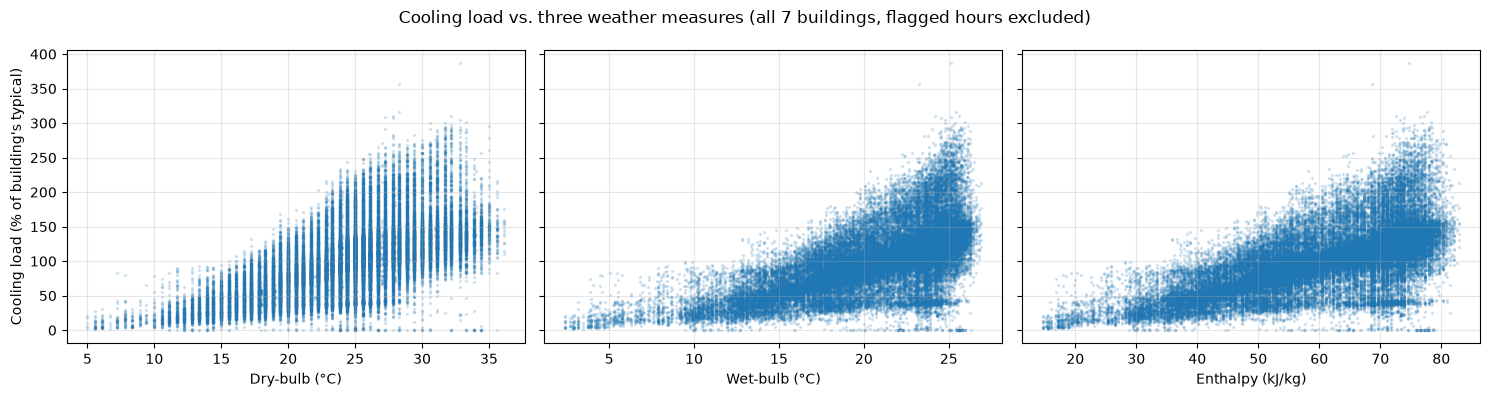

In [23]:
ok = data[data['flag'] == ''].copy()
ok['load_pct_of_typical'] = 100 * ok['meter_reading'] / ok.groupby('building_id')['meter_reading'].transform('median')

features = {'air_temperature': 'Dry-bulb (°C)', 'wet_bulb': 'Wet-bulb (°C)', 'enthalpy': 'Enthalpy (kJ/kg)'}

corr_table = ok.groupby('building_id').apply(
    lambda b: pd.Series({label: b['meter_reading'].corr(b[col]) for col, label in features.items()}),
    include_groups=False
).round(3)
corr_table.loc['median across buildings'] = corr_table.median().round(3)
print("Correlation (r) of cooling load with each weather measure, flagged hours excluded:\n")
print(corr_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (col, label) in zip(axes, features.items()):
    ax.scatter(ok[col], ok['load_pct_of_typical'], s=2, alpha=0.15)
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Cooling load (% of building's typical)")
fig.suptitle('Cooling load vs. three weather measures (all 7 buildings, flagged hours excluded)')
plt.tight_layout()
plt.savefig('figures/load_vs_weather_measures.png', dpi=120)
plt.show()


---

## Section 4: Physics Baseline

In [ ]:
def fit_changepoint_model(df, predictor='wet_bulb'):
    X = df[predictor].values.reshape(-1, 1)
    y = df['meter_reading'].values
    candidates = np.percentile(X, np.linspace(10, 90, 50))
    best_r2 = -np.inf
    best_params = None
    
    for bp in candidates:
        X_transformed = np.column_stack([np.ones(len(X)), np.maximum(0, X.ravel() - bp)])
        try:
            model = LinearRegression(fit_intercept=False)
            model.fit(X_transformed, y)
            y_pred = model.predict(X_transformed)
            ss_res = np.sum((y - y_pred) ** 2)
            ss_tot = np.sum((y - y.mean()) ** 2)
            r2 = 1 - (ss_res / ss_tot)
            if r2 > best_r2:
                best_r2 = r2
                best_params = {'balance_point': bp, 'intercept': model.coef_[0], 'slope': model.coef_[1], 'r2': r2, 'model': model}
        except:
            continue
    return best_params

models = {}
print(f"{'Building':<10} {'Balance Pt (°C)':<18} {'Intercept':<15} {'Slope':<12} {'R²':<8}")
print("-" * 65)

for b_id in SELECTED_BUILDINGS:
    b_data = data[data['building_id'] == b_id].copy()
    model_params = fit_changepoint_model(b_data, predictor='wet_bulb')
    models[b_id] = model_params
    print(f"{b_id:<10} {model_params['balance_point']:>16.1f}  {model_params['intercept']:>13.0f}  {model_params['slope']:>10.2f}  {model_params['r2']:>7.3f}")

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

for idx, b_id in enumerate(SELECTED_BUILDINGS):
    b_data = data[data['building_id'] == b_id].copy()
    params = models[b_id]
    sort_idx = np.argsort(b_data['wet_bulb'].values)
    X_sorted = b_data['wet_bulb'].values[sort_idx]
    y_sorted = b_data['meter_reading'].values[sort_idx]
    y_pred = params['intercept'] + params['slope'] * np.maximum(0, X_sorted - params['balance_point'])
    
    ax = axes[idx]
    ax.scatter(X_sorted, y_sorted, alpha=0.4, s=20, label='Observed')
    ax.plot(X_sorted, y_pred, 'r-', linewidth=2.5, label='Change-point model')
    ax.axvline(params['balance_point'], color='orange', linestyle='--', linewidth=2, label=f"Balance Pt: {params['balance_point']:.1f}°C")
    ax.set_xlabel('Wet Bulb (°C)')
    ax.set_ylabel('Cooling Load (kWh)')
    ax.set_title(f"Building {b_id} (R² = {params['r2']:.3f})")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()
print("✓ Change-point models fit and visualized")

In [ ]:
# Calculate residuals
data['baseline_pred'] = np.nan
data['residual'] = np.nan

for b_id in SELECTED_BUILDINGS:
    b_mask = data['building_id'] == b_id
    params = models[b_id]
    X_b = data.loc[b_mask, 'wet_bulb'].values
    baseline = params['intercept'] + params['slope'] * np.maximum(0, X_b - params['balance_point'])
    residual = data.loc[b_mask, 'meter_reading'].values - baseline
    data.loc[b_mask, 'baseline_pred'] = baseline
    data.loc[b_mask, 'residual'] = residual

print(f"Residual statistics:")
print(f"  Mean: {data['residual'].mean():.1f} kWh")
print(f"  Std:  {data['residual'].std():.1f} kWh")
print(f"  Min:  {data['residual'].min():.1f} kWh")
print(f"  Max:  {data['residual'].max():.1f} kWh")